# MetricSuite 4 -- Effect sizes, estimates and non-inferiority

A p-value says whether a difference is distinguishable from chance. It doesn't say
**how large** the difference is -- and with enough data, any tiny difference becomes
significant. This tutorial is about the size:

- **Part 1** -- why p-values aren't enough;
- **Part 2** -- the effect sizes each test reports, with their confidence intervals;
- **Part 3** -- `suite.estimate`: estimates without a test (per group, other
  estimators);
- **Part 4** -- offsets and non-inferiority ("not worse by more than δ");
- **Part 5** -- ties: `zero_method`.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from mindmap.metric import MetricSuite
from mindmap.metric.results import PairwiseResult

COLORS = {"wCSET": "#2a78d6", "CSET": "#1baf7a", "dSPM": "#e34948"}

### The fake study

40 patients, three methods. `wCSET` is about as accurate as `CSET` (0.5 mm better on
average) and clearly better than `dSPM` (6 mm). Errors are in mm, lower is better.

In [2]:
TRUE_ERROR = {"wCSET": 13.5, "CSET": 14.0, "dSPM": 20.0}
rng = np.random.default_rng(4)
suite = MetricSuite(name="Effect sizes")
for p in range(40):
    difficulty = rng.normal(0, 5)
    for method, mu in TRUE_ERROR.items():
        err = max(mu + difficulty + rng.normal(0, 2.0), 0.5)
        suite.register("loc_error_mm", err, method=method, patient=f"P{p:02d}")

comparisons = suite.stat.build_comparisons("wCSET", ["CSET", "dSPM"])

## 📏 - Part 1: Why p-values aren't enough

Run the same test on the first 10 patients, then on all 40. The p-value for `dSPM`
drops by orders of magnitude; the effect sizes -- the rank-biserial `r` and the
Hodges-Lehmann estimate in mm -- stay in the same range (the n = 40 values are just
more precise). The effect is a property of the methods; the p-value also depends on
how many patients you happened to include.

In [3]:
first_10 = {"patient": [f"P{p:02d}" for p in range(10)]}
kws = dict(group_by="method", comparisons=comparisons, pairing_col="patient",
           effect_sizes=("rank_biserial", "hodges_lehmann"))
small = suite.stat.wilcoxon("loc_error_mm", filters=first_10, **kws)
large = suite.stat.wilcoxon("loc_error_mm", **kws)

columns = ["p_value", "rank_biserial", "hodges_lehmann"]
small.vs("wCSET", higher_is_better=False)[columns].join(
    large.vs("wCSET", higher_is_better=False)[columns], lsuffix=" (n=10)", rsuffix=" (n=40)").round(4)

,p_value (n=10),rank_biserial (n=10),hodges_lehmann (n=10),p_value (n=40),rank_biserial (n=40),hodges_lehmann (n=40)
method,,,,,,
CSET,0.375,0.3455,0.8641,0.1922,0.239,0.6296
dSPM,0.002,1.0000,8.0530,0.0000,1.000,6.9877


Report both: the test for "is there a difference?", the effect size -- with its
interval -- for "how large?".

## 📐 - Part 2: The effect sizes each test reports

Two kinds:

- **unstandardized**, in the metric's own units -- what a clinician understands:
  `hodges_lehmann` (HL, the robust "typical difference"), `mean_diff`, and
  `prop_diff` for 0/1 outcomes;
- **standardized**, unitless -- comparable across metrics and studies:
  `rank_biserial` (r), `cohens_dz` / `hedges_gz` (paired), `cohens_d` / `hedges_g`,
  `cles` (independent), `odds_ratio` (0/1 outcomes).

Each test allows the ones that match it; the first is its default:

In [4]:
PairwiseResult.EFFECT_SIZES

{'wilcoxon': ('rank_biserial', 'hodges_lehmann'),
 'mcnemar': ('prop_diff', 'odds_ratio'),
 'paired_ttest': ('cohens_dz', 'hedges_gz', 'mean_diff'),
 'ttest_ess': ('cohens_dz', 'hedges_gz', 'mean_diff'),
 'ttest': ('cohens_d', 'hedges_g', 'mean_diff'),
 'mannwhitneyu': ('rank_biserial', 'cles', 'hodges_lehmann')}

The ones you'll use most:

| effect size | definition | reads as |
|---|---|---|
| `hodges_lehmann` (paired) | median of the Walsh averages `(d_i + d_j) / 2` | typical difference, robust to outliers |
| `mean_diff` | mean of the differences | average difference |
| `rank_biserial` (paired) | `(R+ - R-) / (R+ + R-)` over the ranks of \|d\| (Kerby 2014) | from -1 to 1: share of favourable minus unfavourable, weighted by size |
| `cohens_dz` | `mean(d) / sd(d)` | difference in units of its own variability |
| `cles` (independent) | `P(a > b) + P(a = b)/2` | probability a random `a` beats a random `b` (0.5 = none) |

Request any allowed set with `effect_sizes`. Each becomes a column -- **with its 95%
confidence interval** (`<name>_ci_low`, `<name>_ci_high`):

In [5]:
wil = suite.stat.wilcoxon("loc_error_mm", **kws, correction="holm")
tt = suite.stat.paired_ttest("loc_error_mm", "method", comparisons, pairing_col="patient", correction="holm",
                             effect_sizes=("cohens_dz", "hedges_gz", "mean_diff"))
wil.vs("wCSET", higher_is_better=False).round(3)

,p_value,p_corrected,significant,rank_biserial,rank_biserial_ci_low,rank_biserial_ci_high,hodges_lehmann,hodges_lehmann_ci_low,hodges_lehmann_ci_high,offset,alternative,n_pairs,n_zero
method,,,,,,,,,,,,,
CSET,0.192,0.192,False,0.239,-0.112,0.576,0.630,-0.360,1.395,0.0,two-sided,40,0
dSPM,0.000,0.000,True,1.000,1.000,1.000,6.988,6.162,8.027,0.0,two-sided,40,0


In [6]:
tt.vs("wCSET", higher_is_better=False).round(3)

,p_value,p_corrected,significant,cohens_dz,cohens_dz_ci_low,cohens_dz_ci_high,hedges_gz,hedges_gz_ci_low,hedges_gz_ci_high,mean_diff,mean_diff_ci_low,mean_diff_ci_high,offset,alternative,n_pairs,n_zero
method,,,,,,,,,,,,,,,,
CSET,0.136,0.136,False,0.241,-0.071,0.550,0.236,-0.067,0.552,0.625,-0.206,1.455,0.0,two-sided,40,0
dSPM,0.000,0.000,True,2.594,2.154,3.336,2.543,2.126,3.290,7.071,6.199,7.943,0.0,two-sided,40,0


`vs` orients every effect size so positive = reference better -- and its interval
with it (the bounds swap). A probability-scale effect size flips as `1 - v`
(`cles`), a ratio as `1 / v` (`odds_ratio`), the others as `-v`.

### Where the intervals come from

An effect size from a sample is an *estimate*, so it gets a confidence interval.
Each one is computed the best available way:

| effect size | interval |
|---|---|
| `mean_diff` | t (paired) / Welch (independent); with `ttest_ess`, the effective sample size |
| `hodges_lehmann` | exact signed-rank (paired, n ≤ 200) / Mann-Whitney (independent) |
| `prop_diff`, `odds_ratio` | Newcombe / exact (tutorial 5) |
| `rank_biserial`, `cohens_dz`, `cles`, ... | no textbook interval: percentile **bootstrap** (tutorial 6) |

`result.ci_methods` says which was used, and `result.ci_seed` records the
bootstrap's seed, so the intervals can be reproduced:

In [7]:
wil.ci_methods, wil.ci_seed, tt.ci_methods

({'rank_biserial': 'bootstrap', 'hodges_lehmann': 'analytic'},
 269129659529926248055432300400237151537,
 {'cohens_dz': 'bootstrap', 'hedges_gz': 'bootstrap', 'mean_diff': 'analytic'})

Two options on every test:

- `ci_level` (default 0.95) sets the coverage. It is separate from `alpha`, the
  significance threshold: e.g. a one-sided test at 0.05 matches a 90% interval.
- `ci=False` skips the intervals -- faster when only the p-values matter.

`ttest_ess`'s standardized effect sizes get no interval: a plain bootstrap would
ignore the autocorrelation that test corrects for (its `mean_diff` keeps the
corrected t interval).

One caveat with bootstrapped intervals: when every patient favours the same method
(here `dSPM`, r = 1), every resample does too, so the interval collapses to
[1, 1]. Report such an r as "all patients favoured wCSET" and rely on the
unstandardized effect (HL) and its interval for the size.

## 🎯 - Part 3: `suite.estimate` -- estimates without a test

The test reports the intervals of *its* effect sizes. `suite.estimate.<name>`
computes any estimate on its own -- with the same functions, so the numbers always
agree -- for what a test doesn't give you:

- a summary of each group (its mean, median, proportion);
- an effect size the test didn't report, or another interval (`alpha`,
  `ci_method="bootstrap"`);
- an `EstimateResult` to draw with `plot.estimate`.

### Per group

In [8]:
suite.estimate.median("loc_error_mm", group_by="method").table

,group,estimate,ci_low,ci_high,n,ci_method
0,CSET,14.152189,10.453059,15.862415,40,binomial_exact
1,dSPM,18.929531,16.498458,22.330308,40,binomial_exact
2,wCSET,12.525748,9.662865,16.072825,40,binomial_exact


In [9]:
suite.estimate.mean("loc_error_mm", group_by="method").table

,group,estimate,ci_low,ci_high,n,ci_method
0,CSET,13.347209,11.529805,15.164613,40,t
1,dSPM,19.793940,17.866660,21.721221,40,t
2,wCSET,12.722668,11.026420,14.418915,40,t


The per-group intervals: t for the mean, exact binomial (order statistics) for the
median, Wilson for a proportion.

### Differences

Differences take `comparisons` and, when paired, `pairing_col` -- the same
arguments as a test. The interval is analytic by default
(`ci_method="analytic"`):

In [10]:
hl = suite.estimate.hodges_lehmann("loc_error_mm", "method", comparisons, pairing_col="patient")
hl

EstimateResult(metric='loc_error_mm', estimator='hodges_lehmann', ci=95%, n_rows=2)
  wCSET vs CSET: -0.6296 [-1.395, 0.3601]
  wCSET vs dSPM: -6.988 [-8.027, -6.162]

In [11]:
hl.vs("wCSET", higher_is_better=False)

,estimate,ci_low,ci_high,n_reference,n_competitor
method,,,,,
CSET,0.629630,-0.360127,1.394521,40,40
dSPM,6.987747,6.162229,8.026937,40,40


A standardized effect size has no analytic interval, so `suite.estimate` asks for
the bootstrap explicitly (the tests fall back to it on their own):

In [12]:
try:
    suite.estimate.cohens_dz("loc_error_mm", "method", comparisons, pairing_col="patient")
except NotImplementedError as e:
    print(e)
suite.estimate.cohens_dz("loc_error_mm", "method", comparisons, pairing_col="patient",
                         ci_method="bootstrap", seed=0).table

No analytic confidence interval is implemented for 'cohens_dz' -- pass ci_method='bootstrap' for a bootstrap interval, or ci=False for its point value.


,group_a,group_b,estimate,ci_low,ci_high,n_a,n_b,ci_method,n_boot
0,wCSET,CSET,-0.240531,-0.556313,0.071475,40,40,bootstrap_percentile,10000
1,wCSET,dSPM,-2.593613,-3.364009,-2.165765,40,40,bootstrap_percentile,10000


### From a test: `from_result`

To get an `EstimateResult` for exactly the units a test saw -- its pairing, filters
and units -- use `suite.estimate.from_result(result)`. By default it estimates the
unstandardized effect that goes with the test (`result.estimator`): HL for a
Wilcoxon test, the mean difference for a t-test. Its numbers are the ones already
in the test's table:

In [13]:
wil.estimator, suite.estimate.from_result(wil).vs("wCSET", higher_is_better=False)

('hodges_lehmann',
         estimate    ci_low   ci_high  n_reference  n_competitor
 method                                                         
 CSET    0.629630 -0.360127  1.394521           40            40
 dSPM    6.987747  6.162229  8.026937           40            40)

### Drawing estimates

`plot.estimate` draws an `EstimateResult`; `plot.paired_differences` draws the
per-patient differences with the test's own estimate and interval on top (the black
mark) -- read from the test's table.

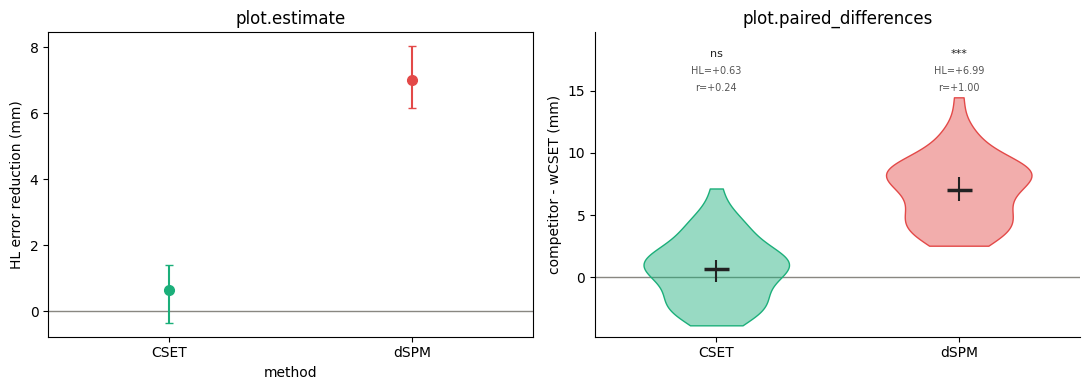

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
suite.plot.estimate(hl, reference="wCSET", higher_is_better=False, palette=COLORS, ax=axes[0],
                    ylabel="HL error reduction (mm)", title="plot.estimate")
suite.plot.paired_differences(wil, higher_is_better=False, palette=COLORS, ax=axes[1],
                              annotate=("stars", "hodges_lehmann", "rank_biserial"),
                              ylabel="competitor - wCSET (mm)", title="plot.paired_differences")
fig.tight_layout()

## 🛡️ - Part 4: Offsets and non-inferiority

### The question

`wCSET` vs `CSET` isn't significant. That does **not** show they're equivalent --
absence of evidence isn't evidence of absence. If the claim is "`wCSET` is not
worse than `CSET`", test it directly: pick a margin δ -- the largest loss you'd
accept, decided *before* looking at the data, e.g. δ = 2 mm -- and test

H0: wCSET is worse by δ or more, vs H1: wCSET is worse by less than δ.

### The test: `offset` + `alternative`

Every test (except McNemar) takes `offset`: `group_a - group_b` is tested against it
instead of 0. Here `wCSET - CSET < 2 mm` is `offset=2, alternative="less"`:

In [15]:
delta = 2.0
noninf = suite.stat.wilcoxon(
    "loc_error_mm", "method", [("wCSET", "CSET")], pairing_col="patient",
    offset=delta, alternative="less", zero_method="pratt", effect_sizes=("rank_biserial", "hodges_lehmann"),
)
superiority = suite.stat.wilcoxon(
    "loc_error_mm", "method", [("wCSET", "CSET")], pairing_col="patient",
    zero_method="pratt", effect_sizes=("rank_biserial", "hodges_lehmann"),
)
cols = ["group_a", "group_b", "p_value", "hodges_lehmann"]
pd.concat([
    noninf.table[cols].assign(offset=noninf.offset, alternative=noninf.alternative),
    superiority.table[cols].assign(offset=superiority.offset, alternative=superiority.alternative),
], keys=["non-inferiority", "superiority"])

,,group_a,group_b,p_value,hodges_lehmann,offset,alternative
non-inferiority,0,wCSET,CSET,1.937588e-07,-0.62963,2.0,less
superiority,0,wCSET,CSET,1.921960e-01,-0.62963,0.0,two-sided


Non-inferiority holds (small p); superiority doesn't. Note that **effect sizes
ignore the offset** -- HL is the same in both results. The offset only changes the
hypothesis, hence the p-value.

`vs` re-expresses the hypothesis with "positive = reference better": for an error,
"wCSET - CSET < 2" becomes "CSET - wCSET > -2", i.e. `offset=-2,
alternative="greater"` -- "wCSET is better by more than -2 mm":

In [16]:
noninf.vs("wCSET", higher_is_better=False)

,p_value,p_corrected,significant,rank_biserial,rank_biserial_ci_low,rank_biserial_ci_high,hodges_lehmann,hodges_lehmann_ci_low,hodges_lehmann_ci_high,offset,alternative,n_pairs,n_zero
method,,,,,,,,,,,,,
CSET,1.937588e-07,1.937588e-07,True,0.239024,-0.112195,0.57561,0.62963,-0.360127,1.394521,-2.0,greater,40,0


### The interval tells the same story

Read the HL interval -- already in the result -- against δ. The whole interval lies
above -2 mm (reference orientation): every plausible value of the difference is a
loss smaller than δ. The interval also contains 0: no evidence of superiority.

In [17]:
noninf.vs("wCSET", higher_is_better=False)[["hodges_lehmann", "hodges_lehmann_ci_low", "hodges_lehmann_ci_high", "offset"]]

,hodges_lehmann,hodges_lehmann_ci_low,hodges_lehmann_ci_high,offset
method,,,,
CSET,0.62963,-0.360127,1.394521,-2.0


For the figure on the left, `plot.estimate` needs an `EstimateResult`:
`from_result` builds it from the test.

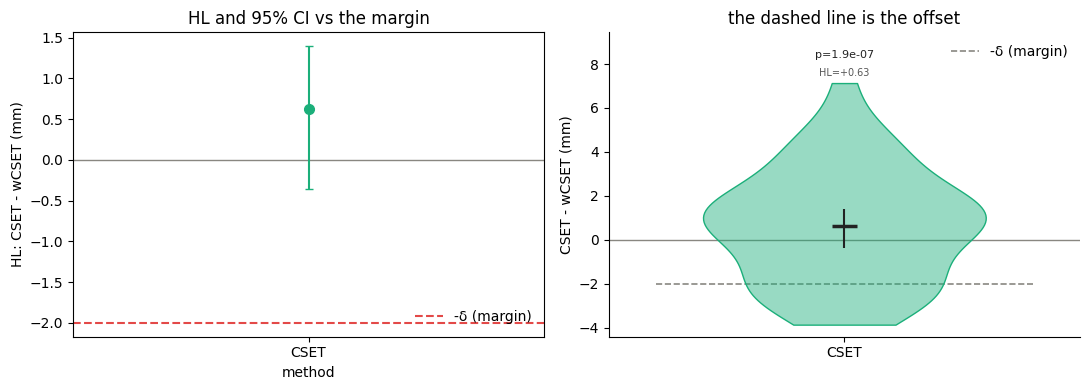

In [18]:
noninf_hl = suite.estimate.from_result(noninf)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
suite.plot.estimate(noninf_hl, reference="wCSET", higher_is_better=False, palette=COLORS, ax=axes[0],
                    reference_lines={"-δ (margin)": (-delta, "#e34948")},
                    ylabel="HL: CSET - wCSET (mm)", title="HL and 95% CI vs the margin")
axes[0].legend(frameon=False, loc="lower right")
suite.plot.paired_differences(noninf, higher_is_better=False, palette=COLORS, ax=axes[1],
                              annotate=("p", "hodges_lehmann"), ylabel="CSET - wCSET (mm)",
                              labels={"offset": "-δ (margin)"}, title="the dashed line is the offset")
fig.tight_layout()

Two notes:

- A one-sided 0.05 test matches a two-sided **90%** interval. Reporting the 95%
  interval (`alpha=0.05`) is the stricter, more common convention -- here both
  agree.
- Plan the margin and the direction in advance, and correct across all your
  non-inferiority comparisons (`correction="holm"`).
- `paired_differences` draws the offset by itself, already oriented like the
  differences, with a legend entry (`labels={"offset": ...}` renames it,
  `offset_kws` restyles it, `show_offset=False` hides it). `plot.estimate` draws
  estimates only, so there the margin is a `reference_lines` entry.

## 🔁 - Part 5: Ties and `zero_method`

### When differences are exactly 0

Some metrics have many exact ties. Take the distance from the estimated source to
the resected area: 0 whenever the peak falls inside the resection. When both methods
land inside for a patient -- here, about half the patients are easy and both methods
succeed -- the difference is exactly 0. Among the other patients, `wCSET` is closer
more often.

In [19]:
rng = np.random.default_rng(145)
ties = MetricSuite(name="Ties")
for p in range(30):
    if rng.random() < 0.45:                       # an easy patient: both methods inside
        distances = {"wCSET": 0.0, "CSET": 0.0}
    else:
        distances = {"wCSET": 0.0 if rng.random() < 0.3 else rng.gamma(2.0, 4.0),
                     "CSET": 0.0 if rng.random() < 0.1 else rng.gamma(2.0, 5.5)}
    for method, distance in distances.items():
        ties.register("distance_mm", distance, method=method, patient=f"P{p:02d}")

Wilcoxon's signed-rank test must decide what to do with the zeros. `zero_method`:

- `"wilcox"` (default) -- **drop** them. The test asks "among the patients where the
  methods differ, which one wins?". `n_pairs` shrinks.
- `"pratt"` -- **keep** them: rank them (lowest), then leave their ranks out of both
  sums. Ties stay in the sample, so many ties weaken the evidence -- "across all
  patients". Usually the safer choice for an outcome with many ties.
- `"zsplit"` -- keep them and split their ranks evenly between both sums.

`n_zero` counts the ties. The rank-biserial follows the same convention: with
`"pratt"` / `"zsplit"`, the zeros' ranks stay in its denominator, so ties pull r
toward 0 (both give the same r).

In [20]:
rows = []
for zm in ["wilcox", "pratt", "zsplit"]:
    r = ties.stat.wilcoxon("distance_mm", "method", [("wCSET", "CSET")], pairing_col="patient", zero_method=zm)
    rows.append(r.table.assign(zero_method=zm)[["zero_method", "n_pairs", "n_zero", "p_value", "rank_biserial"]])
pd.concat(rows, ignore_index=True)

,zero_method,n_pairs,n_zero,p_value,rank_biserial
0,wilcox,17,13,0.021682,-0.633987
1,pratt,30,13,0.081291,-0.348387
2,zsplit,30,13,0.092510,-0.348387


Here the choice changes the conclusion. Among the patients where the methods differ,
`wCSET` wins clearly (`"wilcox"`); across **all** patients, half of them ties, the
evidence is weaker and r is pulled toward 0 (`"pratt"`/`"zsplit"`). Both answers are
correct -- to different questions.

The `"counts"` annotation of `paired_differences` shows the raw picture -- how many
patients favour the reference, tie, or favour the competitor:

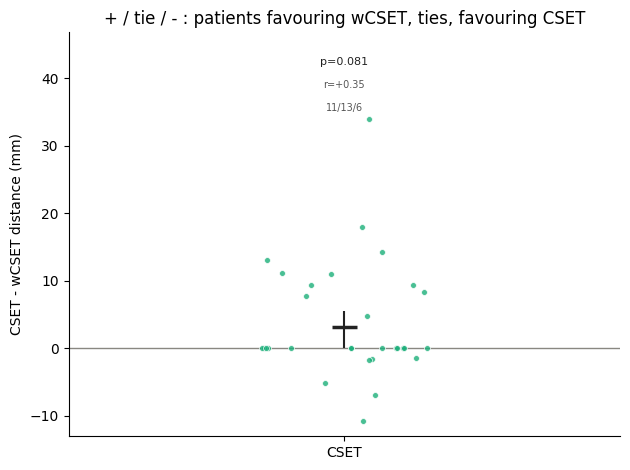

In [21]:
pratt = ties.stat.wilcoxon("distance_mm", "method", [("wCSET", "CSET")], pairing_col="patient",
                           zero_method="pratt", effect_sizes=("rank_biserial", "hodges_lehmann"))
fig, ax = ties.plot.paired_differences(
    pratt, higher_is_better=False, palette=COLORS, kind="strip",
    annotate=("p", "effect", "counts"), ylabel="CSET - wCSET distance (mm)",
    title="+ / tie / - : patients favouring wCSET, ties, favouring CSET",
)
fig.tight_layout()

Which to report? Decide in advance. `"pratt"` answers the question about all
patients and is the conservative choice with many ties; state the number of ties
either way. For an outcome that is *mostly* "inside or not", consider the binary
version too -- McNemar, tutorial 5.

## Wrap-up

- p-values depend on n; **effect sizes don't**. Report both, with an interval.
- Each test reports the effect sizes that match it (`effect_sizes=`), **each with
  a confidence interval** (`ci_level`, `ci=False` to skip; analytic when one
  exists, bootstrap otherwise -- `ci_methods`). Unstandardized ones (HL, mean
  difference) are in the metric's units.
- `suite.estimate.<name>` for estimates without a test: per-group summaries, other
  estimators or intervals; `from_result` turns a test into an `EstimateResult`
  (e.g. for `plot.estimate`).
- **Non-inferiority**: `offset=δ` + the right `alternative`; read the HL interval
  against δ. Offsets never change effect sizes.
- **Ties**: `zero_method="pratt"` keeps them in the analysis; `n_zero` reports
  them.

Next: **tutorial 5** -- binary outcomes.